<a href="https://colab.research.google.com/github/05haileywang/econ3916_midtermproject/blob/main/midterm_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 Midterm Project — Econometric Foundation

**ECON 3916 · Applied Data Analytics** · Topics 1-14 · 100 points · your role: Independent analyst

This is the **starter**: the structure of the project in rubric order. Fill the empty cells and keep every heading so the grader finds each section. The brief on Canvas has the full text of every section and the rubric. The grader reruns this notebook from the top, so every number, table and figure in your report must come from a cell here.

**🛑 This project is entirely NO AI.** Not phases one to three — all of it. No AI for the code, the analysis, the writing, or the editing. This is the one assessment in the course that establishes you can do the work unaided, and it is the one you will draw on when an interviewer asks what you built. Everything you have practised with a co-pilot, you do here alone.

## Start here

Work top to bottom. What each part of this notebook is for:

1. **Data provenance**: where the file came from. It feeds Section 1 and your README.
2. **Section 1**: load the data into a DataFrame called `df`, then run the *Section 1 self-check* cell and answer the questions under it. Do this before the **Mon 2 Nov** checkpoint.
3. **Section 2**: figures, each with a caption that states a finding.
4. **Section 3**: the OLS model, with a draft committed by **Fri 6 Nov**.
5. **Section 4**: diagnostics, only after Topic 14.
6. **Section 5**: words only.
7. **Numbers my report quotes**: last. Every number in the report must be printed there.

The brief's *Six checks before you post* list the problems that came up most often in Checkpoint 1. Read them before you settle on your controls.

## Setup

Imports only. Add any others you need here, at the top.

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

## Data provenance

Fill these in when you download the data. They feed Section 1 and your README.

In [16]:
SOURCE_URL = "https://data.ny.gov/Transportation/MTA-Bridges-and-Tunnels-Hourly-Crossings-Beginning/ebfx-2m7v/data_preview"
DOWNLOAD_DATE = "2026-10-26"
FILE_NAME = "ECON 3916 NYC Congestion Pricing .xlsx"

**Who collected it, for what purpose, what is missing and why?**

The dataset is from the Metropolitan Transportation Authority, which is the government division that operates, maintains, and develops the public transportation system in NYC, and they collect traffic information to monitor bridge and tunnel usage. The dataset that I chose is one that specifically monitors the bridges and tunnels across NYC, accounting for vehicle type, day of the week, etc.

I narrowed my focus to the Hugh L. Carey Tunnel and the Queens Midtown Tunnel, since those are two of the tunnels that were impacted by the congestion pricing. The original dataset recorded in ten minute intervals, which I then aggregated to daily vehicle counts. I filtered the dataset to include 6 months before and after the implementation of the congestion tax, which was January 5, 2025. The dataset contains 2,920 observations and each row represents the number of vehicles in each vehicle class that passed one of the two tunnels that I am looking at on a given day.

There are no missing values in my cleaned dataset. The MTA has done a thorough job of recording the data. However, I am missing two other tunnels that were impacted by the congestion pricing, which are the Lincoln Tunnel and the Holland Tunnel. They were not included in the analysis because I was unable to find suitable data to compare with the other tunnels.


## Section 1: The Question and the Data (20 pts)

State the question in one sentence, and say why it matters and to whom. Describe the data as a product of measurement decisions, name the missingness mechanism (MCAR, MAR or MNAR) and defend the label. Build a summary-statistics table a reader can read without asking you a question.

In [17]:
df = pd.read_excel(FILE_NAME, sheet_name="NYC_Congestion_Pricing_6_Months")

# Convert date column
df["Date"] = pd.to_datetime(df["Date"])

print("Dataset dimensions:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nFirst five observations:")
display(df.head())
print("\nMissing values:")
print(df.isnull().sum())
print("\nDate range:")
print(df["Date"].min(), df["Date"].max())

Dataset dimensions: (2920, 6)

Column names:
['Date', 'Day of Week', 'Facility', 'Vehicle Class Category', 'Total Traffic Count', 'Congestion Pricing']

First five observations:


,Date,Day of Week,Facility,Vehicle Class Category,Total Traffic Count,Congestion Pricing
0,2024-07-05,Friday,Hugh L. Carey Tunnel,Bus,513,0
1,2024-07-05,Friday,Hugh L. Carey Tunnel,Car,25461,0
2,2024-07-05,Friday,Hugh L. Carey Tunnel,Motorcycle,105,0
3,2024-07-05,Friday,Hugh L. Carey Tunnel,Truck,494,0
4,2024-07-05,Friday,Queens Midtown Tunnel,Bus,239,0



Missing values:
Date                      0
Day of Week               0
Facility                  0
Vehicle Class Category    0
Total Traffic Count       0
Congestion Pricing        0
dtype: int64

Date range:
2024-07-05 00:00:00 2025-07-04 00:00:00


In [18]:
# Section 1 self-check: run once your data is loaded into a DataFrame called df.
# It prints what Section 1 has to report. It doesn't judge your choices: answer the questions below.
UNIT = "date-tunnel-vehicle class"
OUTCOME = "Total Traffic Count"
MAIN_X = "Congestion Pricing"
CONTROLS = ["Vehicle Class Category", "Day of Week", "Facility"]

if "df" in globals():
    print(f"Rows: {len(df):,}   Columns: {df.shape[1]}   One row is: {UNIT or '(fill in UNIT)'}")
    cols = [c for c in [OUTCOME, MAIN_X, *CONTROLS] if c]
    absent = [c for c in cols if c not in df.columns]
    if absent:
        print("Not in df:", absent)
    present = [c for c in cols if c in df.columns]
    if present:
        print("\nMissing values per column:")
        print(df[present].isna().sum().to_string())
    if OUTCOME in df.columns and pd.api.types.is_numeric_dtype(df[OUTCOME]):
        print(f"\nSkew of {OUTCOME}: {df[OUTCOME].skew():.2f} (above about 1, consider a log)")
else:
    print("Load your data into a DataFrame called df first, then run this cell.")

Rows: 2,920   Columns: 6   One row is: date-tunnel-vehicle class

Missing values per column:
Total Traffic Count       0
Congestion Pricing        0
Vehicle Class Category    0
Day of Week               0
Facility                  0

Skew of Total Traffic Count: 1.32 (above about 1, consider a log)


**Answer before you go on.**

1. For each control: does your main explanatory variable change it? If yes, it is on the path from X to Y. Drop it, or run with and without and say what each version measures.
2. Are all your variables in the same units and for the same years?
3. If your question is about a policy, where is the period before it?

*Your answers here.*

1. My main explanatory variable is congestion pricing, and my controls are vehicle class, day of the week, and facility. Congestion pricing would not affect the day of the week or the location of the facility, so I will keep these as controls. Congestion pricing could influence the composition of vehicles entering the CRZ, so I will consider this when interpreting my results. I will use two different regression models. The first will use congestion pricing as the only explanatory variable. I will then include vehicle class, day of the week, and facility in a second model, which will help me understand the relationship between congestion pricing and traffic volume while accounting for differences across these categories.

2. All of the variables are measured consistently across observations, although they use different units. The dependent variable measures the daily number of vehicles passing through each tunnel by vehicle class. Congestion pricing is a binary variable, where 0 is before congestion pricing, and 1 is after congestion pricing. Vehicle class, day of the week, and facility are categorical variables.

3. NYC implemented congestion pricing on January 5, 2025. My dataset includes approximately 6 months before and 6 months after congestion pricing was implemented. I narrowed it down to this timeframe to examine changes in traffic volumes surrounding the implementation of the policy. The data from before January 5 can serve as a baseline for traffic volumes before congestion pricing was implemented. However, differences between the two periods could also reflect other factors, such as seasonal traffic patterns.

## Section 2: Descriptive Evidence (20 pts)

Show the reader the data before any model. At least two figures, each with a caption that states its finding, not its variables. Chapter 3's standards for axes. If the outcome is skewed, show it and say what you will do about it.

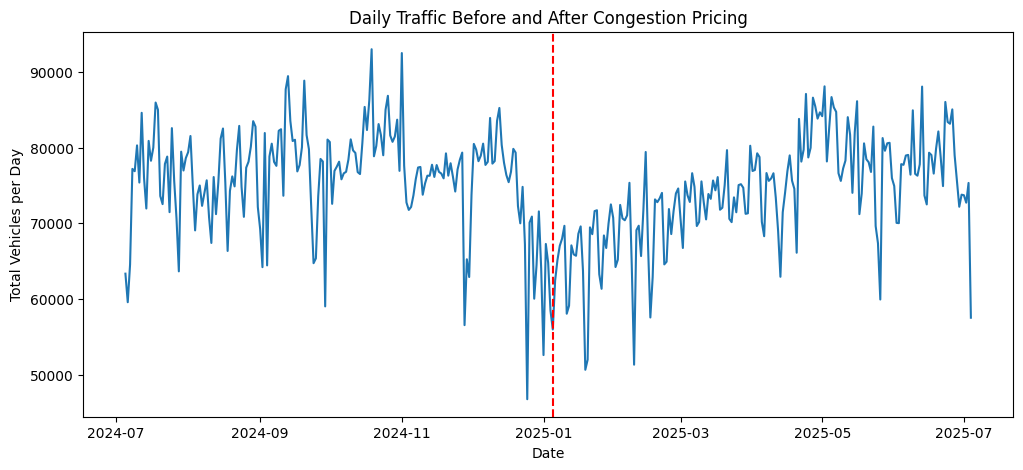

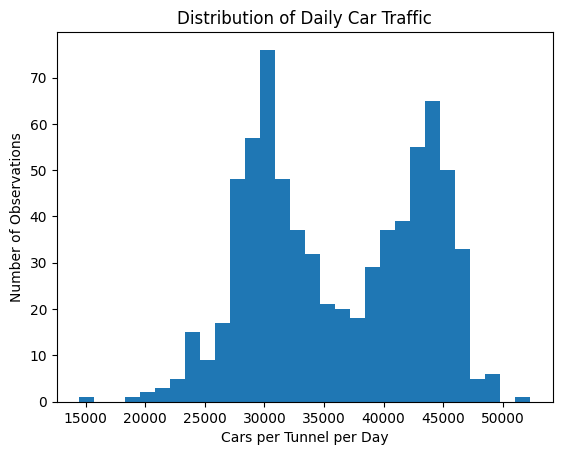

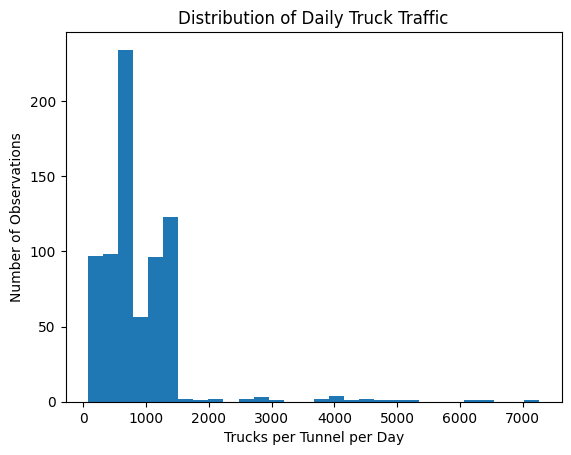

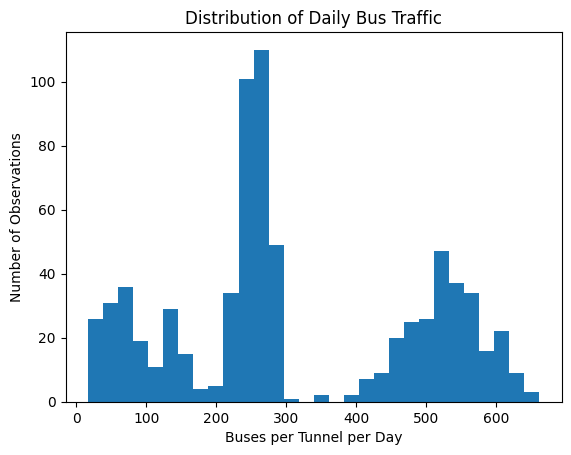

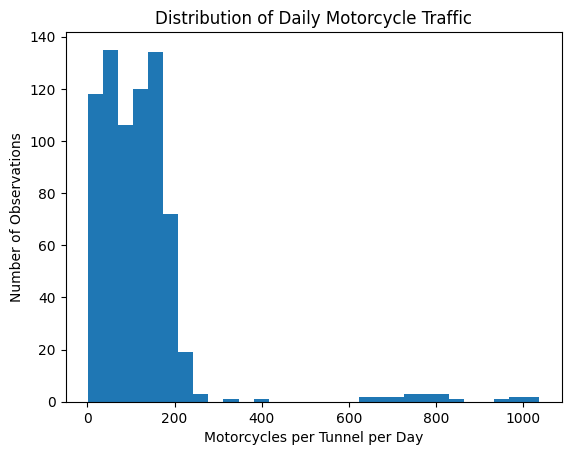

Overall skewness: 1.319
Car skewness: -0.042
Truck skewness: 3.987
Bus skewness: 0.21
Motorcycle skewness: 4.193


In [19]:
# Traffic volumes before and after the congestion tax
daily = df.groupby("Date")["Total Traffic Count"].sum()

plt.figure(figsize=(12, 5))
plt.plot(daily)

plt.axvline(pd.Timestamp("2025-01-05"), color="red", linestyle="--")

plt.title("Daily Traffic Before and After Congestion Pricing")
plt.xlabel("Date")
plt.ylabel("Total Vehicles per Day")
plt.show()

# Distribution of traffic counts by vehicle class
cars = df[df["Vehicle Class Category"] == "Car"]

plt.hist(cars["Total Traffic Count"], bins=30)
plt.title("Distribution of Daily Car Traffic")
plt.xlabel("Cars per Tunnel per Day")
plt.ylabel("Number of Observations")
plt.show()

trucks = df[df["Vehicle Class Category"] == "Truck"]

plt.hist(trucks["Total Traffic Count"], bins=30)
plt.title("Distribution of Daily Truck Traffic")
plt.xlabel("Trucks per Tunnel per Day")
plt.ylabel("Number of Observations")
plt.show()

buses = df[df["Vehicle Class Category"] == "Bus"]

plt.hist(buses["Total Traffic Count"], bins=30)
plt.title("Distribution of Daily Bus Traffic")
plt.xlabel("Buses per Tunnel per Day")
plt.ylabel("Number of Observations")
plt.show()

motorcycles = df[df["Vehicle Class Category"] == "Motorcycle"]

plt.hist(motorcycles["Total Traffic Count"], bins=30)
plt.title("Distribution of Daily Motorcycle Traffic")
plt.xlabel("Motorcycles per Tunnel per Day")
plt.ylabel("Number of Observations")
plt.show()

print("Overall skewness:", round(df["Total Traffic Count"].skew(), 3))
print("Car skewness:", round(cars["Total Traffic Count"].skew(), 3))
print("Truck skewness:", round(trucks["Total Traffic Count"].skew(), 3))
print("Bus skewness:", round(buses["Total Traffic Count"].skew(), 3))
print("Motorcycle skewness:", round(motorcycles["Total Traffic Count"].skew(), 3))

In [20]:

import pandas as pd
import matplotlib.pyplot as plt

# Summary statistics
print("Number of observations:", len(df))
print("Mean:", round(df["Total Traffic Count"].mean(), 3))
print("Median:", round(df["Total Traffic Count"].median(), 3))
print("Standard deviation:", round(df["Total Traffic Count"].std(), 3))
print("Minimum:", df["Total Traffic Count"].min())
print("Maximum:", df["Total Traffic Count"].max())
print("Overall skewness:", round(df["Total Traffic Count"].skew(), 3))

# Skewness by vehicle class
for vehicle in ["Car", "Bus", "Truck", "Motorcycle"]:
    data = df[df["Vehicle Class Category"] == vehicle]
    print(vehicle, "skewness:", round(data["Total Traffic Count"].skew(), 3))

# Average daily traffic before and after congestion pricing
daily = df.groupby(["Date", "Congestion Pricing"])["Total Traffic Count"].sum().reset_index()

before = daily[daily["Congestion Pricing"] == 0]["Total Traffic Count"].mean()
after = daily[daily["Congestion Pricing"] == 1]["Total Traffic Count"].mean()

print("\nAverage daily traffic before:", round(before, 3))
print("Average daily traffic after:", round(after, 3))
print("Percentage change:", round((after - before) / before * 100, 3), "%")


Number of observations: 2920
Mean: 9368.036
Median: 517.0
Standard deviation: 15874.177
Minimum: 2
Maximum: 52319
Overall skewness: 1.319
Car skewness: -0.042
Bus skewness: 0.21
Truck skewness: 3.987
Motorcycle skewness: 4.193

Average daily traffic before: 76162.576
Average daily traffic after: 73705.812
Percentage change: -3.226 %


*Your words here.*
Figure 1 shows the volume of traffic before and after congestion pricing was implemented on January 5, 2025, in the Hugh L. Carey Tunnel and the Queens Midtown Tunnel. Based on the graph, right after January 5, 2025, traffic declined sharply. However, traffic volume gradually increased over time, almost to pre-congestion pricing levels. The average daily traffic count was around 76,163 vehicles before congestion pricing and then decreased to around 73,706 afterwards. This represents approximately a 3.23 percent decrease in traffic volumes. This suggests that congestion pricing may have contributed to a reduction in traffic, but the observed decrease could also be attributed to other factors.

Figure 2 shows the distribution of daily traffic counts across four different vehicle classes: cars, trucks, buses, and motorcycles. The overall mean traffic count is 9,368.036 vehicles, while the median is 517 vehicles per observation, where each observation represents one vehicle class at one tunnel on a given day. Since the mean is substantially larger than the median, this suggests that the distribution is positively skewed. The overall skewness is 1.319, which is consistent with this observation. Cars are relatively symmetric, with a skewness of -0.042. Buses are also relatively symmetric, with a skewness of 0.210. The truck and motorcycle distributions are strongly positively skewed, with values of 3.987 and 4.193, respectively. There are a small number of observations with unusually high traffic counts that could potentially be considered outliers. Most observations for trucks and motorcycles are clustered around lower traffic counts.

The overall distribution of traffic volume is positively skewed; however, vehicle classes have different traffic volumes, which contributes to the overall skewness. Cars account for the largest share of traffic and substantially outnumber buses, trucks, and motorcycles. Although a logarithmic transformation could be helpful, I will choose to maintain the data in its original form. This will allow me to interpret the regression coefficients in terms of the number of vehicles passing through the tunnels. I will include vehicle class as an explanatory variable in the regression.

## Section 3: The Model (25 pts)

Fit a multivariate OLS model and report it in a formatted regression table (coefficients, standard errors, N, R-squared), not a `summary()` dump. Interpret at least two coefficients in full: magnitude, units, direction, precision. For every control, say whether it blocks a confounding path or adds precision, and what would make it a bad control (Chapter 10). OLS only: no difference-in-differences estimate.

In [26]:
import statsmodels.formula.api as smf
from statsmodels.iolib.summary2 import summary_col

# Model 1: Base model

model1 = smf.ols(
    'Q("Total Traffic Count") ~ Q("Congestion Pricing")',
    data=df
).fit()

# Model 2: Extended model

model2 = smf.ols(
    'Q("Total Traffic Count") ~ Q("Congestion Pricing") + '
    'C(Q("Vehicle Class Category"), Treatment(reference="Car")) + '
    'C(Q("Day of Week"), Treatment(reference="Sunday")) + '
    'C(Facility)',
    data=df
).fit()

# HC3 robust standard errors for Model 2

model2_hc3 = model2.get_robustcov_results(cov_type="HC3")

# Formatted regression table

table = summary_col(
    [model1, model2_hc3],
    stars=True,
    model_names=["Base Model", "Extended Model"],
    info_dict={
        "N": lambda x: f"{int(x.nobs)}"
    },
    float_format="%.3f"
)

results = table.tables[0].copy()

# Shorten variable names

names = {
    "Intercept": "Constant",
    'Q("Congestion Pricing")': "Congestion Pricing",

    'C(Q("Vehicle Class Category"), Treatment(reference="Car"))[T.Bus]': "Bus",
    'C(Q("Vehicle Class Category"), Treatment(reference="Car"))[T.Motorcycle]': "Motorcycle",
    'C(Q("Vehicle Class Category"), Treatment(reference="Car"))[T.Truck]': "Truck",

    'C(Q("Day of Week"), Treatment(reference="Sunday"))[T.Monday]': "Monday",
    'C(Q("Day of Week"), Treatment(reference="Sunday"))[T.Tuesday]': "Tuesday",
    'C(Q("Day of Week"), Treatment(reference="Sunday"))[T.Wednesday]': "Wednesday",
    'C(Q("Day of Week"), Treatment(reference="Sunday"))[T.Thursday]': "Thursday",
    'C(Q("Day of Week"), Treatment(reference="Sunday"))[T.Friday]': "Friday",
    'C(Q("Day of Week"), Treatment(reference="Sunday"))[T.Saturday]': "Saturday",

    "C(Facility)[T.Queens Midtown Tunnel]": "Queens Midtown Tunnel"
}

results = results.rename(index=names)

display(results)

# Key regression results

pricing = 'Q("Congestion Pricing")'

pricing_index = model2.model.exog_names.index(pricing)

print("\nBASE MODEL")
print("Congestion Pricing Coefficient:",
      round(model1.params[pricing], 3))
print("Standard Error:",
      round(model1.bse[pricing], 3))
print("P-value:",
      round(model1.pvalues[pricing], 4))
print("R-squared:",
      round(model1.rsquared, 4))
print("Observations:", int(model1.nobs))


print("\nEXTENDED MODEL (HC3)")
print("Congestion Pricing Coefficient:",
      round(model2.params[pricing], 3))
print("Robust Standard Error:",
      round(model2_hc3.bse[pricing_index], 3))
print("Robust P-value:",
      round(model2_hc3.pvalues[pricing_index], 4))
print("R-squared:",
      round(model2.rsquared, 4))
print("Observations:", int(model2.nobs))

# 95% confidence interval

ci = model2_hc3.conf_int(alpha=0.05)[pricing_index]

print("\n95% CONFIDENCE INTERVAL")
print("Lower bound:", round(ci[0], 3))
print("Upper bound:", round(ci[1], 3))

,Base Model,Extended Model
Constant,9520.322***,34155.932***
,(413.801),(285.370)
Congestion Pricing,-307.095,-307.410***
,(587.623),(118.182)
Bus,,-35837.389***
,,(222.760)
Motorcycle,,-36024.359***
,,(221.569)
Truck,,-35261.844***
,,(219.734)



BASE MODEL
Congestion Pricing Coefficient: -307.095
Standard Error: 587.623
P-value: 0.6013
R-squared: 0.0001
Observations: 2920

EXTENDED MODEL (HC3)
Congestion Pricing Coefficient: -307.41
Robust Standard Error: 118.182
Robust P-value: 0.0093
R-squared: 0.9598
Observations: 2920

95% CONFIDENCE INTERVAL
Lower bound: -539.139
Upper bound: -75.68


My main explanatory variable is congestion pricing, and my dependent variable is the number of vehicles that pass through the Hugh L. Carey Tunnel and the Queens Midtown Tunnel. I will use the ordinary least squares regression method to examine my research question. The first model will only examine the change in vehicle volumes before and after congestion pricing was implemented. The second model will additionally control for day of the week, facility, and vehicle class.

All of the variables are measured consistently across observations, although they use different units. The dependent variable measures the daily number of vehicles passing through each tunnel by vehicle class. Congestion pricing is a binary variable, where 0 is before congestion pricing, and 1 is after congestion pricing. Vehicle class, day of the week, and facility are categorical variables.

The day of the week is included because traffic volumes generally vary throughout the week, as there are work commuters during the week and tourist traffic volumes entering the city on the weekends. Controlling for these differences could help to improve the fit of the regression and the R-squared value. The policy does not have an impact on the day of the week; it is unlikely to be a bad control.

The facility is included because the Hugh L. Carey Tunnel and the Queens Midtown Tunnel serve the financial district and Midtown East, respectively. Accounting for the difference in commuter patterns and traffic patterns can help to improve the model. Since congestion pricing does not determine which tunnels exist, the facility is unlikely to be a bad control; however, the policy could change commuter behavior.

Vehicle class is included because cars, buses, trucks, and motorcycles have different traffic volumes (See Figure 2). Commuters are likely to use cars and buses to get to work, while trucks are primarily used for deliveries across the city. Controlling for vehicle class allows us to isolate the effects of these differences. If congestion pricing does impact the types and volumes of each vehicle class, then it could impact the result. We should proceed with caution.

NYC implemented congestion pricing on January 5, 2025. My dataset includes approximately 6 months before and 6 months after congestion pricing. I narrowed it down to this timeframe to examine changes in traffic volumes surrounding the implementation of the policy. The data from before January 5 can serve as a baseline for traffic volumes before congestion
pricing was implemented.

Model 1: Base regression
Traffic - hat = β₀ + β₁Post + εᵢ
Traffic - hat = 9,520.32 + -307.1Post + εᵢ

The first model will focus simply on the relationship between congestion pricing and traffic volumes. β₀ is equal to 9,520.32, which is the average expected number of vehicles per observation before congestion pricing. β₁ is equal to -307.10, which indicates that the average traffic volume per vehicle class, facility, and day was approximately 307 vehicles lower after congestion pricing was implemented.
At the 5% level, the coefficient of β₁ is not statistically significant (p = 0.601), indicating that there is insufficient evidence to conclude that average traffic volumes differed between the two periods.

Extended model:
Traffic - hat = β₀ + β₁Post +β₂ Day + β₃Facility + εᵢ
Traffic - hat = 34,155.93 - 307.41Post +β₂ Day + β₃Facility β₄Vehicle + εᵢ

The second model adds controls for the day of the week, facility, and vehicle class. Day of the week accounts for different traffic patterns throughout the week, as traffic volumes differ on each day of the week. The facility differentiates between the Hugh L. Carey Tunnel and the Queens Midtown Tunnel. Hugh L. Carey Tunnel enters Manhattan through the Financial District in the south. The Queens-Midtown tunnel traffic flows from Queens into Midtown East. Vehicle class was included as a control because cars, buses, trucks, and motorcycles have different traffic volumes.

For this model, I used Sunday as the reference day, Hugh L. Carey Tunnel as the reference facility, and Car as the reference vehicle class. The coefficients for the remaining categorical variables are interpreted in relation to these reference categories to avoid producing results with perfect multicollinearity.

β₀: The expected average traffic volume for car traffic at the Hugh L. Carey Tunnel on a Sunday before congestion pricing is 34,155.93.
β₁: Average traffic volume decreased by 307 (rounded down to the nearest whole vehicle) vehicles per observation after congestion pricing was implemented, holding day of week, facility, and vehicle class constant.
β₂: The coefficients suggest that traffic volumes are generally higher on weekdays compared to the weekend. The coefficients for weekdays are positive, suggesting that there is more traffic volume on weekdays compared to Sunday. Saturday also has a positive coefficient, but the coefficient is smaller than the rest of the week, suggesting that while Saturday has more traffic volume compared to Sunday, there is still more traffic on weekdays.
β₃: The coefficient on facility indicates that the expected average traffic volume for the Queens Midtown Tunnel is 3,172 more than the Hugh L. Carey Tunnel, holding day of week, facility, and vehicle class constant.
β₄: The coefficient on vehicle type indicates that there are substantially fewer buses, motorcycles, and trucks compared to the reference, which is cars.

At the 5% level, the coefficient of β₁ is statistically significant (p = 0.009), indicating that traffic volumes were lower after congestion pricing was implemented, holding day of the week, facility, and vehicle class constant. The 95% confidence interval is [−539.04, −75.78]. This relationship does not necessarily establish causation, as other factors could influence traffic volumes.

The extended model produced an R-squared value of 0.960, which is interpreted as 96 percent of the variation in traffic volume can be explained by the model. This is an improvement over the R-squared value produced by the base regression, which was close to 0. However, even though we included additional explanatory variables in the extended regression, it can still be affected by omitted variable bias. This provides that there is a correlation, but not necessarily causation, and does not eliminate omitted variable bias.

## Section 4: Diagnostics (20 pts)

Residuals against fitted values and against your main predictor; a constant-variance check, with robust standard errors if it fails; variance inflation factors, interpreted; at least one influential-observation check.

**Start only after Topic 14.** Write Sections 1 to 3 first; they do not depend on it.

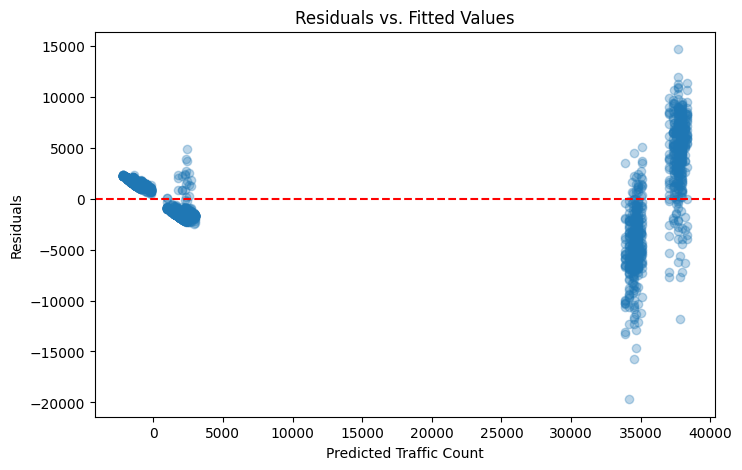

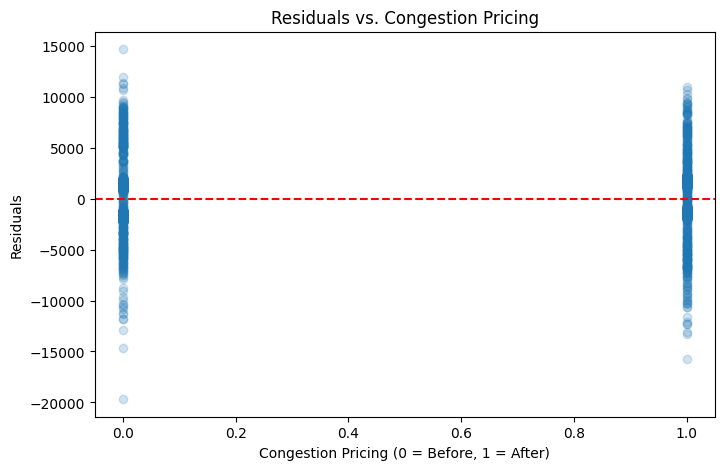

Breusch-Pagan p-value: 0.0

Congestion Pricing Coefficient and Standard Errors:
Coefficient: -307.41
Original SE: 118.028
Robust SE: 118.182
Robust p-value: 0.009

Variance Inflation Factors:


,Variable,VIF
0,Intercept,1.000
1,"C(Q(""Vehicle Class Category""), Treatment(refer...",1.500
2,"C(Q(""Vehicle Class Category""), Treatment(refer...",1.500
3,"C(Q(""Vehicle Class Category""), Treatment(refer...",1.500
4,"C(Q(""Day of Week""), Treatment(reference=""Sunda...",1.726
5,"C(Q(""Day of Week""), Treatment(reference=""Sunda...",1.715
6,"C(Q(""Day of Week""), Treatment(reference=""Sunda...",1.715
7,"C(Q(""Day of Week""), Treatment(reference=""Sunda...",1.715
8,"C(Q(""Day of Week""), Treatment(reference=""Sunda...",1.715
9,"C(Q(""Day of Week""), Treatment(reference=""Sunda...",1.715


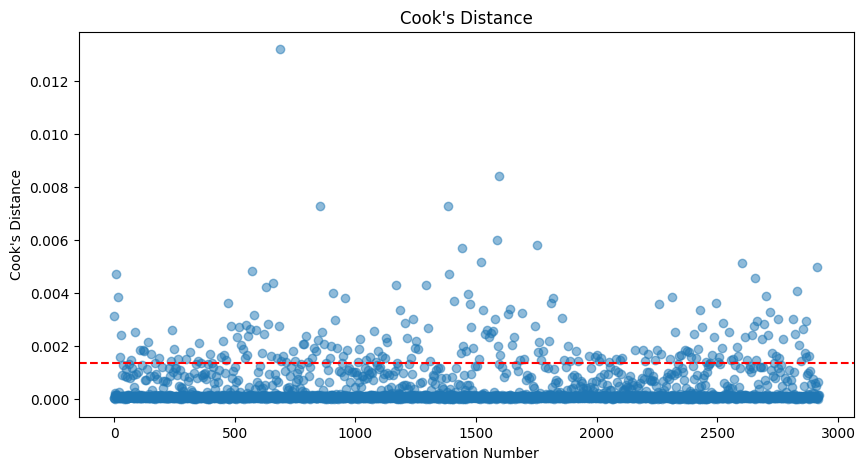

Cook's Distance threshold: 0.00137
Observations above threshold: 216
Original congestion pricing coefficient: -307.41
Coefficient after excluding flagged observations: 31.489
Observations remaining: 2704


In [22]:
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor, OLSInfluence

# Residuals vs. Fitted Values

plt.figure(figsize=(8, 5))
plt.scatter(model2.fittedvalues, model2.resid, alpha=0.3)
plt.axhline(0, color="red", linestyle="--")
plt.title("Residuals vs. Fitted Values")
plt.xlabel("Predicted Traffic Count")
plt.ylabel("Residuals")
plt.show()

# Residuals vs. Congestion Pricing

plt.figure(figsize=(8, 5))
plt.scatter(df["Congestion Pricing"], model2.resid, alpha=0.2)
plt.axhline(0, color="red", linestyle="--")
plt.title("Residuals vs. Congestion Pricing")
plt.xlabel("Congestion Pricing (0 = Before, 1 = After)")
plt.ylabel("Residuals")
plt.show()

# Breusch-Pagan Test for Heteroskedasticity

bp = het_breuschpagan(model2.resid, model2.model.exog)

print("Breusch-Pagan p-value:", round(bp[1], 3))

# Robust standard errors
robust_model = model2.get_robustcov_results(cov_type="HC3")

print("\nCongestion Pricing Coefficient and Standard Errors:")

pricing = model2.model.exog_names.index('Q("Congestion Pricing")')

print("Coefficient:", round(model2.params.iloc[pricing], 3))
print("Original SE:", round(model2.bse.iloc[pricing], 3))
print("Robust SE:", round(robust_model.bse[pricing], 3))
print("Robust p-value:", round(robust_model.pvalues[pricing], 3))

# VIF

X = pd.DataFrame(
    model2.model.exog,
    columns=model2.model.exog_names
)

vif = pd.DataFrame()

vif["Variable"] = X.columns
vif["VIF"] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

print("\nVariance Inflation Factors:")
display(vif.round(3))

# Cook's Distance

influence = OLSInfluence(model2)
cooks = influence.cooks_distance[0]

plt.figure(figsize=(10, 5))
plt.scatter(range(len(cooks)), cooks, alpha=0.5)
plt.axhline(4 / len(df), color="red", linestyle="--")
plt.title("Cook's Distance")
plt.xlabel("Observation Number")
plt.ylabel("Cook's Distance")
plt.show()

print("Cook's Distance threshold:", round(4 / len(df), 5))
print("Observations above threshold:", sum(cooks > 4 / len(df)))

# Sensitivity check
df_check = df.loc[cooks <= 4 / len(df)].copy()

model2_check = smf.ols(
    model2.model.formula,
    data=df_check
).fit()

print("Original congestion pricing coefficient:",
      round(model2.params['Q("Congestion Pricing")'], 3))

print("Coefficient after excluding flagged observations:",
      round(model2_check.params['Q("Congestion Pricing")'], 3))

print("Observations remaining:", len(df_check))

*Your words here.*

## Section 5: Threats and Conclusion (10 pts)

First the threats: what would have to be true for your main coefficient to be causal, is it, and if not, what your estimate is instead. Then the conclusion: what you found, how confident a reader should be, and what you would do with another month. Half a page. No new results, so there is no code cell here.

*Your words here.*
One of the main limitations of the analysis is that the regression results can help to establish correlation, not causality. Additionally, my dataset only includes Hugh L. Carey Tunnel and the Queens Midtown Tunnel. It does not include other tunnels that are a part of New York City’s congestion piercing initiative, such as the Lincoln Tunnel and the Holland Tunnel. My results are limited in their scope and cannot be generalized to all changes to traffic entering Manhattan.
After removing 216 influential observations using the Cook’s distance method, the sensitivity analysis estimated that the coefficient on congestion pricing changed from -307.41 to 31.49. The regression analysis that included all of the observations may be sensitive to these extreme values and can be influencing the outcome of the regression. These observations cannot be removed from the analysis, as they may be representative of real fluctuations in traffic volumes.
My analysis finds that average daily traffic decreased by 3.23 percent after congestion pricing was implemented. The based regression produced a coefficient of -301.10, which is not statistically significant at the 5% level. After including vehicle class, day of the week, and facility, the coefficient was -307.41 and was statistically significant. The sensitivity analysis concluded that influential observation could have had an impact on the regression. I cannot confidently conclude that congestion pricing caused a reduction in traffic volume.
With additional bandwidth, I would expand the analysis to other tunnels impacted by congestion pricing. It would be interesting to see if roads not impacted by congestion pricing saw higher traffic volumes because drivers were taking alternative routes. I think this could help provide a more reliable estimate of the policy’s impact.

## Appendix

The regression table, the diagnostics output and any extra figures. The appendix does not count toward the 6–8 page limit of the report.

## Numbers my report quotes

Every number in your report, each with a name that says where it comes from. A number in the report that this cell does not print is unsupported, and is graded as if it were missing. Keep it the last code cell.

In [23]:
REPORT_NUMBERS = {
    # "Section 1: rows in the final sample": ...,
    # "Section 3: coefficient on <your main predictor>": ...,
}

for name, value in REPORT_NUMBERS.items():
    print(f"{name}: {value}")

In [32]:

import pandas as pd
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor, OLSInfluence

# Section 2: Descriptive statistics
before = df[df["Congestion Pricing"] == 0]
after = df[df["Congestion Pricing"] == 1]

daily = df.groupby(["Date", "Congestion Pricing"])["Total Traffic Count"].sum().reset_index()

before_mean = daily[daily["Congestion Pricing"] == 0]["Total Traffic Count"].mean()
after_mean = daily[daily["Congestion Pricing"] == 1]["Total Traffic Count"].mean()

percent_change = (after_mean - before_mean) / before_mean * 100

# Section 3: Regression results
pricing = 'Q("Congestion Pricing")'

robust_model = model2.get_robustcov_results(cov_type="HC3")
pricing_index = model2.model.exog_names.index(pricing)
ci = robust_model.conf_int(alpha=0.05)[pricing_index]

# Section 4: Diagnostics
bp = het_breuschpagan(model2.resid, model2.model.exog)

X = pd.DataFrame(model2.model.exog, columns=model2.model.exog_names)

vif_values = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

cooks = OLSInfluence(model2).cooks_distance[0]
threshold = 4 / int(model2.nobs)

# All numbers quoted in the report
REPORT_NUMBERS = {
    "Section 1: Number of observations": len(df),
    "Section 1: Number of columns": df.shape[1],
    "Section 1: Missing values": int(df.isna().sum().sum()),

    "Section 2: Average daily traffic before pricing": round(before_mean, 3),
    "Section 2: Average daily traffic after pricing": round(after_mean, 3),
    "Section 2: Percentage change in traffic": round(percent_change, 3),
    "Section 2: Overall skewness": round(df["Total Traffic Count"].skew(), 3),

    "Section 3: Base model coefficient": round(model1.params[pricing], 3),
    "Section 3: Base model standard error": round(model1.bse[pricing], 3),
    "Section 3: Base model p-value": round(model1.pvalues[pricing], 4),
    "Section 3: Base model R-squared": round(model1.rsquared, 4),

    "Section 3: Extended model coefficient": round(model2.params[pricing], 3),
    "Section 3: Extended model standard error": round(robust_model.bse[pricing_index], 3),
    "Section 3: Extended model p-value": round(robust_model.pvalues[pricing_index], 4),
    "Section 3: Extended model R-squared": round(model2.rsquared, 4),
    "Section 3: 95% CI lower": round(ci[0], 3),
    "Section 3: 95% CI upper": round(ci[1], 3),

    "Section 4: Breusch-Pagan p-value": round(bp[1], 6),
    "Section 4: HC3 robust standard error": round(robust_model.bse[pricing_index], 3),
    "Section 4: HC3 robust p-value": round(robust_model.pvalues[pricing_index], 4),
    "Section 4: Maximum VIF excluding intercept": round(max(vif_values[1:]), 3),
    "Section 4: Cook's distance threshold": round(threshold, 5),
    "Section 4: Observations above Cook's threshold": int(sum(cooks > threshold)),
    "Section 4: Percentage above Cook's threshold": round(sum(cooks > threshold) / int(model2.nobs) * 100, 3),
    "Section 4: Coefficient after removing influential observations": round(model2_check.params[pricing], 3),
    "Section 4: Observations remaining": int(model2_check.nobs)
}

for name, value in REPORT_NUMBERS.items():
    print(f"{name}: {value}")

Section 1: Number of observations: 2920
Section 1: Number of columns: 6
Section 1: Missing values: 0
Section 2: Average daily traffic before pricing: 76162.576
Section 2: Average daily traffic after pricing: 73705.812
Section 2: Percentage change in traffic: -3.226
Section 2: Overall skewness: 1.319
Section 3: Base model coefficient: -307.095
Section 3: Base model standard error: 587.623
Section 3: Base model p-value: 0.6013
Section 3: Base model R-squared: 0.0001
Section 3: Extended model coefficient: -307.41
Section 3: Extended model standard error: 118.182
Section 3: Extended model p-value: 0.0093
Section 3: Extended model R-squared: 0.9598
Section 3: 95% CI lower: -539.139
Section 3: 95% CI upper: -75.68
Section 4: Breusch-Pagan p-value: 0.0
Section 4: HC3 robust standard error: 118.182
Section 4: HC3 robust p-value: 0.0093
Section 4: Maximum VIF excluding intercept: 1.726
Section 4: Cook's distance threshold: 0.00137
Section 4: Observations above Cook's threshold: 216
Section 4: P

## Checkpoints

In Colab, *File › Save a copy in GitHub* makes a commit each time you use it. Save at each checkpoint so the commit history shows it.

- [ ] **Mon 26 Oct:** your question and data source, posted in the Midterm checkpoint 1 discussion.
- [ ] **Mon 2 Nov:** your data loaded and your summary table, committed to your repository.
- [ ] **Fri 6 Nov:** a draft of your model, committed.
- [ ] **Mon 9 Nov, 11:59pm:** the project is due.

## Before you submit

- [ ] A Colab notebook with all your analysis, cleanly organised.
- [ ] A written report, 6 to 8 pages of text, uploaded as a PDF.
- [ ] A GitHub repository containing both, with a `README.md` you wrote yourself.
- [ ] **Question and data provenance (20):** A defensible measurable question; data described as a measurement product; missingness mechanism identified and defended; interpretable summary table
- [ ] **Descriptive evidence (20):** Two or more figures each making a stated point; captions state findings not variables; Chapter 3 standards met
- [ ] **Model and interpretation (25):** Properly formatted regression table; two coefficients interpreted in full including units and magnitude; every control justified by role
- [ ] **Diagnostics (20):** Residuals, heteroskedasticity, VIF and influence all run and interpreted; robust errors used where warranted
- [ ] **Threats and conclusion (10):** The causal claim assessed in plain terms; the estimand correctly labelled if not causal; conclusion adds no new results
- [ ] **Repository, checkpoints and reproducibility (5):** Public GitHub repo containing the notebook and the report; the two committed checkpoints visible in the commit history; data included or its download documented; a self-written README giving the question, the source, how to run it and the headline finding
- [ ] The Colab notebook is shared with *Anyone with the link*, and the link is in the Canvas submission box.
- [ ] Every number in the report is printed by the *Numbers my report quotes* cell.
- [ ] No AI anywhere: code, analysis, writing, editing, README.
- [ ] *File › Save a copy in GitHub*, path `Midterm Project/Econ_3916_Midterm.ipynb`.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.